# Introduction to Artificial Neural Networks with PyTorch
This notebook covers:
- Activation functions
- Forward & backward propagation
- Gradient descent
- Building a simple neural network
- Loading MNIST
- Visualizing data

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt


## Activation Functions

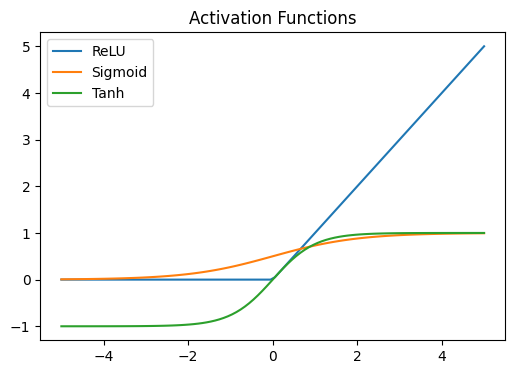

In [2]:
x = torch.linspace(-5, 5, 100)
activations = {
    "ReLU": nn.ReLU(),
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh()
}

plt.figure(figsize=(6,4))
for name, fn in activations.items():
    plt.plot(x, fn(x), label=name)
plt.legend()
plt.title("Activation Functions")
plt.show()

## Forward and Backward Propagation

In [3]:
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(-1.0, requires_grad=True)

x = torch.tensor(3.0)
y_true = torch.tensor(10.0)

y_pred = w * x + b
loss = (y_pred - y_true)**2
loss.backward()

w.grad, b.grad

(tensor(-30.), tensor(-10.))

## Loading MNIST Dataset

100.0%
100.0%
100.0%
100.0%


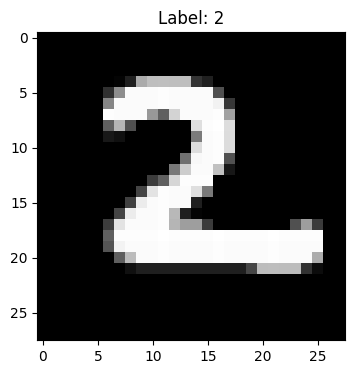

In [4]:
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)

images, labels = next(iter(train_loader))
plt.figure(figsize=(4,4))
plt.imshow(images[0].squeeze(), cmap='gray')
plt.title(f"Label: {labels[0]}")
plt.show()

## Simple Neural Network

In [5]:
class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 10))
    def forward(self, x):
        x = self.flatten(x)
        return self.fc(x)

model = SimpleNN()
optimizer = optim.SGD(model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

images, labels = next(iter(train_loader))
pred = model(images)
loss = loss_fn(pred, labels)
loss.backward()
loss.item()

2.313326597213745

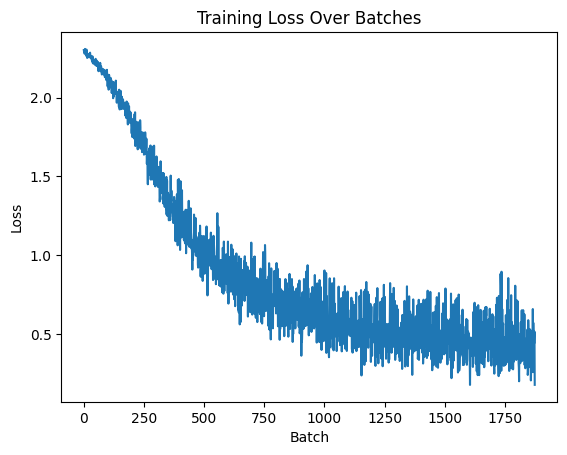

0.1765647828578949

In [6]:
loss_history = []

for batch_idx, (data, target) in enumerate(train_loader):
    optimizer.zero_grad()
    output = model(data)
    loss = loss_fn(output, target)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

plt.plot(loss_history)
plt.title("Training Loss Over Batches")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.show()

loss_history[-1]